In [32]:
import pandas as pd
import numpy as np
import rioxarray as rxr
import rasterio
import matplotlib.pyplot as plt


### Loading all Saved Environmental Layers

In [2]:
dem = rxr.open_rasterio("data_processed/dem_1km_res.tif").squeeze()
dem = dem.where(dem != -32768)

slope = rxr.open_rasterio("data_processed/slope.tif").squeeze()

aspect = rxr.open_rasterio("data_processed/aspect.tif").squeeze()

tern_rgd = rxr.open_rasterio("data_processed/tri.tif").squeeze() # terrain ruggedness

temp = rxr.open_rasterio("data_processed/breeding_temp_1km.tif").squeeze()

In [3]:
# check alignment of shape
print(dem.shape)
print(slope.shape)
print(aspect.shape)
print(tern_rgd.shape)
print(temp.shape)

(301, 801)
(410, 751)
(410, 751)
(410, 751)
(301, 801)


In [4]:
# checking alignment of shape of dem for slope.. 
slope = slope.rio.reproject_match(dem)
slope

<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan, 0.64966017, 0.83665717, ..., 1.2426729 ,        nan,
               nan],
       [       nan, 0.2826757 , 0.42840576, ..., 0.96581453,        nan,
               nan],
       ...,
       [       nan, 0.20544851, 0.3023303 , ..., 0.        ,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]], dtype=float32)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      slope
    _FillValue:     -32768.0

In [5]:
# checking alignment of shape of dem for aspect.. 
aspect = aspect.rio.reproject_match(dem)
aspect

<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan, 211.32869, 208.41266, ...,  88.8876 ,       nan,
              nan],
       [      nan, 219.80557, 237.65256, ..., 117.52522,       nan,
              nan],
       ...,
       [      nan, 356.63354, 298.61047, ...,  -1.     ,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan]], dtype=float32)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      aspect
    _FillValue:     -32768.0

In [6]:
print(float(dem.min()), float(dem.max()))
print(float(temp.min()), float(temp.max()))
print(float(slope.min()), float(slope.max()))
print(float(aspect.min()), float(aspect.max()))
print(float(tern_rgd.min()), float(tern_rgd.max()))

-8.0 4599.0
3.118363618850708 23.23716163635254
0.0 36.384098052978516
-1.0 359.9825439453125
0.0 978.7777709960938


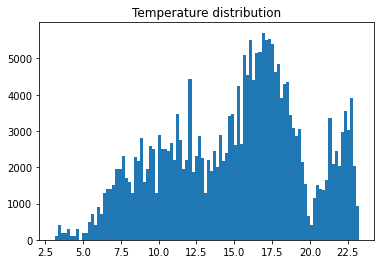

In [7]:
# hist plot of temperature
plt.hist(temp.values.flatten(), bins=100)
plt.title("Temperature distribution")
plt.show()

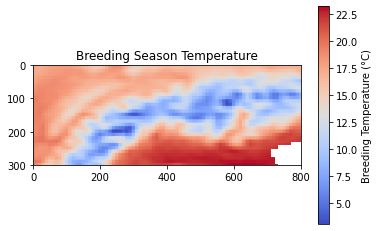

In [8]:
# Visual breakdown of Temperature
plt.imshow(temp, cmap="coolwarm")
plt.colorbar(label="Breeding Temperature (°C)")
plt.title("Breeding Season Temperature")
plt.show()

In [9]:
# Check for NaNs and change them 0
print("DEM NaNs:", int(np.isnan(dem.values).sum()))
print("TEMP NaNs:", int(np.isnan(temp.values).sum()))
print("SLOPE NaNs:", int(np.isnan(slope.values).sum()))
print("Terrain Ruggedness NaNs:", int(np.isnan(tern_rgd.values).sum()))

DEM NaNs: 1101
TEMP NaNs: 4556
SLOPE NaNs: 3297
Terrain Ruggedness NaNs: 2318


In [10]:
dem = dem.fillna(0)
temp = temp.fillna(0)
slope = slope.fillna(0)
aspect = aspect.fillna(0)
tern_rgd = tern_rgd.fillna(0)

### Temperature Suitability for Breeding

In [11]:
# Rock Ptarmigan breeding temperature: 5 °C  ≤ breeding_temp ≤ 12 °C
ref_elevn = 2000
# we have lapse rate yeah! 6.5 K or °C per km
lapse_rate = -6.5/1000
temp_corrected = temp + lapse_rate * (dem - ref_elevn)

habn_temp = ((temp >= 3) & (temp <= 15)).astype(int)
print("Temp pixels:",habn_temp.sum().values)
habn_temp

Temp pixels: 102360


<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    band         int32 4B 1
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
    spatial_ref  int32 4B 0

In [12]:
print("Before correction:", temp.min(), temp.max())
print("After correction:", temp_corrected.min(), temp_corrected.max())

Before correction: <xarray.DataArray ()> Size: 8B
array(0.)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0 <xarray.DataArray ()> Size: 8B
array(23.23716164)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0
After correction: <xarray.DataArray ()> Size: 8B
array(-11.05459404)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0 <xarray.DataArray ()> Size: 8B
array(36.23715973)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0


### Elevation of Breeding Site of Ptarmigan

In [13]:
habn_elev = ((dem >= 1800) & (dem <= 3000)).astype(int)
print("Elevation pixels:",habn_elev.sum().values)
habn_elev

Elevation pixels: 41594


<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    band         int32 4B 1
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
    spatial_ref  int32 4B 0

### Slope for breeding site

In [14]:
habn_slope = (slope <=36).astype(int)
print("Slope pixels:",habn_slope.sum().values)
habn_slope

Slope pixels: 241100


<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]])
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0

### Aspect for breeding site NW and NE Facing Slopes

In [15]:
habn_aspect = ((aspect >= 315) | (aspect <= 45)).astype(int) 
print("Aspect pixels:",habn_aspect.sum().values)
habn_aspect

Aspect pixels: 64449


<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[1, 1, 1, ..., 1, 1, 1],
       [1, 0, 0, ..., 0, 1, 1],
       [1, 0, 0, ..., 0, 1, 1],
       ...,
       [1, 1, 0, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]])
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0

In [16]:
habitat = habn_temp * habn_elev * habn_slope * habn_aspect
print("Habitat pixels:",int(habitat.sum()))
habitat

Habitat pixels: 10545


<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    band         int32 4B 1
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
    spatial_ref  int32 4B 0

In [17]:
habitat = habn_temp & habn_elev & habn_slope & habn_aspect
habitat

<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    band         int32 4B 1
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
    spatial_ref  int32 4B 0

In [18]:
print("Habitat pixels:", habitat.sum())

Habitat pixels: <xarray.DataArray ()> Size: 4B
array(10545)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0


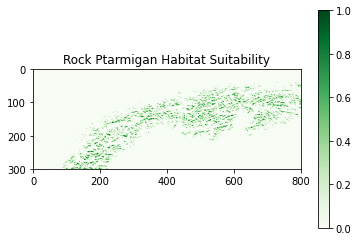

In [19]:
# Visual Spatial Map of habitat
plt.imshow(habitat, cmap="Greens")
plt.title("Rock Ptarmigan Habitat Suitability")
plt.colorbar()
plt.show()

### Baseline Habitat Area

In [20]:
baseline_area = int(habitat.sum())

print("Baseline habitat area (km²):", baseline_area) # A0

Baseline habitat area (km²): 10545


### Future Warming Scenario

In [21]:
future_temp = temp + 2

In [22]:
# New Mask 
future_habitat = ((dem >= 1800) & (dem <= 3000) &
                  (future_temp >= 3) & (future_temp <= 15) &
                  (slope<=36) & ((aspect >= 315) | (aspect <= 45))).astype(int)

future_area = int(future_habitat.sum())

print("Future habitat:", future_area)

Future habitat: 10139


In [23]:
baseline_area = int(habitat.sum())
baseline_area

10545

In [24]:
HCI = future_area / baseline_area
HCI

0.9614983404457089

### Habitat Compression Index

Habitat Compression Index: 0.038501659554291134


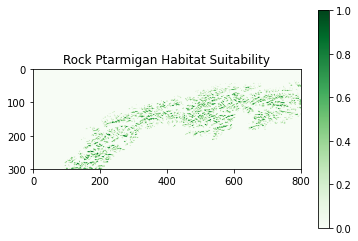

In [25]:
HCI = (baseline_area - future_area) / baseline_area

print("Habitat Compression Index:", HCI)

plt.imshow(future_habitat, cmap="Greens")
plt.title("Rock Ptarmigan Habitat Suitability")
plt.colorbar()
plt.show()

### Processing the Occurence GBIF Data

In [26]:
df = pd.read_csv("data_processed/Rock_Ptarmigan_Occrnc.csv", sep="\t") #occurence data from www.gbif.org
pd.set_option('display.max_columns', None)
df.head()

,gbifID,datasetKey,occurrenceID,kingdom,phylum,class,order,family,genus,species,infraspecificEpithet,taxonRank,scientificName,verbatimScientificName,verbatimScientificNameAuthorship,countryCode,locality,stateProvince,occurrenceStatus,individualCount,publishingOrgKey,decimalLatitude,decimalLongitude,coordinateUncertaintyInMeters,coordinatePrecision,elevation,elevationAccuracy,depth,depthAccuracy,eventDate,day,month,year,taxonKey,speciesKey,basisOfRecord,institutionCode,collectionCode,catalogNumber,recordNumber,identifiedBy,dateIdentified,license,rightsHolder,recordedBy,typeStatus,establishmentMeans,lastInterpreted,mediaType,issue
0,6183598936,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/362525045,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Wallis (VS),Wallis (VS),PRESENT,2.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.028279,7.455767,11.0,NaN,NaN,NaN,NaN,NaN,2025-07-11,11.0,7.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 252570,NaN,NaN,2026-03-31T20:39:56.585Z,NaN,NaN
1,6183463547,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/362490277,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Wallis (VS),Wallis (VS),PRESENT,2.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.028358,7.455630,1.0,NaN,NaN,NaN,NaN,NaN,2025-07-11,11.0,7.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 924943,NaN,NaN,2026-03-31T20:12:32.294Z,NaN,NaN
2,6182988400,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/359776670,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Wallis (VS),Wallis (VS),PRESENT,1.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.579033,8.390598,1.0,NaN,NaN,NaN,NaN,NaN,2025-06-29,29.0,6.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 69441,NaN,NaN,2026-03-31T20:25:20.121Z,NaN,NaN
3,6182580136,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/369680839,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Zernez (Gemeinde),Graubünden (GR),PRESENT,5.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.725304,9.970130,2.0,NaN,NaN,NaN,NaN,NaN,2025-08-12,12.0,8.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 59638,NaN,NaN,2026-03-31T20:13:07.078Z,NaN,NaN
4,6181737025,6ac3f774-d9fb-4796-b3e9-92bf6c81c084,NaN,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Safiental-oberes,NaN,PRESENT,NaN,bb646dff-a905-4403-a49b-6d378c2cf0d9,46.621277,9.256653,25.0,NaN,NaN,NaN,NaN,NaN,2026-03-21T00:00,21.0,3.0,2026.0,5227679,5227679,HUMAN_OBSERVATION,NABU|naturgucker,NABU|naturgucker,773708303,NaN,NaN,NaN,CC_BY_4_0,NaN,1593068209,NaN,NaN,2026-04-03T03:11:35.934Z,NaN,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS8...


In [27]:
# So we have lot of columns we don't need yet so we keep only coordinates, species and year and basis of obsvn for one's
# reference and drop the rest and clean the retained columns
df = df[["species", "locality","decimalLatitude", "decimalLongitude", "year", "basisOfRecord"]]
df

,species,locality,decimalLatitude,decimalLongitude,year,basisOfRecord
0,Lagopus muta,Wallis (VS),46.028279,7.455767,2025.0,HUMAN_OBSERVATION
1,Lagopus muta,Wallis (VS),46.028358,7.455630,2025.0,HUMAN_OBSERVATION
2,Lagopus muta,Wallis (VS),46.579033,8.390598,2025.0,HUMAN_OBSERVATION
3,Lagopus muta,Zernez (Gemeinde),46.725304,9.970130,2025.0,HUMAN_OBSERVATION
4,Lagopus muta,Safiental-oberes,46.621277,9.256653,2026.0,HUMAN_OBSERVATION
...,...,...,...,...,...,...
895,Lagopus muta,Valais,46.270000,7.740000,2006.0,HUMAN_OBSERVATION
896,Lagopus muta,Switzerland- Wallis,46.160126,7.367123,2012.0,HUMAN_OBSERVATION
897,Lagopus muta,Graubünden (GR),46.877577,9.266311,2012.0,HUMAN_OBSERVATION
898,Lagopus muta,Graubünden (GR),46.589541,8.685098,2011.0,HUMAN_OBSERVATION


In [28]:
# filter NaN/null values only on location data 
df = df.dropna(subset=["decimalLatitude", "decimalLongitude"])
df = df.drop_duplicates(subset=["decimalLatitude","decimalLongitude"]) # drop duplicates in coordinates

print(df.shape)
df.head()

(846, 6)


,species,locality,decimalLatitude,decimalLongitude,year,basisOfRecord
0,Lagopus muta,Wallis (VS),46.028279,7.455767,2025.0,HUMAN_OBSERVATION
1,Lagopus muta,Wallis (VS),46.028358,7.455630,2025.0,HUMAN_OBSERVATION
2,Lagopus muta,Wallis (VS),46.579033,8.390598,2025.0,HUMAN_OBSERVATION
3,Lagopus muta,Zernez (Gemeinde),46.725304,9.970130,2025.0,HUMAN_OBSERVATION
4,Lagopus muta,Safiental-oberes,46.621277,9.256653,2026.0,HUMAN_OBSERVATION


In [39]:
# We now check resolution of our geo_terrain models

with rasterio.open("data_processed/dem_clipped.tif") as src:
    dem = src.read(1)
    print("CRS:", src.crs)
    print("Resolution:", src.res)

CRS: EPSG:4326
Resolution: (0.0002777777777778146, 0.00027777777777781486)
